In [1]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

from scipy.optimize import minimize, minimize_scalar, brentq
from scipy.stats import chi2, norm

np.random.seed(42)

# Lens names and deflector redshifts
names = [
    "WGD 2038-4008",
    "RX J1131-1231",
    "PG 1115+080",
    "SDSS J1433+6007",
    "HE 0435-1223",
    "J1537-3010",
    "DES J0408-5354",
    "B1608+656",
    "WFI 2033-4723",
    "HE 1104-1805",
    "SDSS J1206+4332"
]

z = np.array([
    0.228, 0.295, 0.310, 0.407, 0.455,
    0.590, 0.597, 0.630, 0.657, 0.729, 0.745
])

# Published central H0 values, in km/s/Mpc
H0 = np.array([
    65.0, 78.2, 81.1, 73.2, 71.7,
    75.5, 74.2, 71.0, 71.6, 64.2, 68.9
])

# Original lower and upper uncertainties
sigma_minus = np.array([
    14.0, 3.4, 7.1, 4.7, 4.5,
    5.8, 3.0, 3.3, 4.9, 5.0, 5.1
])

sigma_plus = np.array([
    23.0, 3.4, 8.0, 4.8, 4.8,
    9.3, 2.7, 2.9, 3.8, 5.8, 5.4
])

# Errors from Table I after propagating the assumed
# lambda_int scatter for lenses with lambda_int fixed to 1.
sigma_minus_mst = np.array([
    15.0, 7.8, 10.2, 4.7, 7.9,
    5.8, 7.3, 7.2, 8.1, 7.6, 8.0
])

sigma_plus_mst = np.array([
    24.0, 7.8, 10.8, 4.8, 8.0,
    9.3, 7.2, 7.0, 7.5, 8.2, 8.2
])

# True means lambda_int was fitted rather than fixed to 1
lambda_free = np.array([
    False, False, False, True, False,
    True, False, False, False, False, False
])

lambda_fixed = ~lambda_free

# Put everything into a table
lenses = pd.DataFrame({
    "Lens": names,
    "zd": z,
    "H0": H0,
    "sigma_minus": sigma_minus,
    "sigma_plus": sigma_plus,
    "sigma_minus_MST": sigma_minus_mst,
    "sigma_plus_MST": sigma_plus_mst,
    "lambda_int_free": lambda_free
})

display(lenses)

,Lens,zd,H0,sigma_minus,sigma_plus,sigma_minus_MST,sigma_plus_MST,lambda_int_free
0,WGD 2038-4008,0.228,65.0,14.0,23.0,15.0,24.0,False
1,RX J1131-1231,0.295,78.2,3.4,3.4,7.8,7.8,False
2,PG 1115+080,0.310,81.1,7.1,8.0,10.2,10.8,False
3,SDSS J1433+6007,0.407,73.2,4.7,4.8,4.7,4.8,True
4,HE 0435-1223,0.455,71.7,4.5,4.8,7.9,8.0,False
5,J1537-3010,0.590,75.5,5.8,9.3,5.8,9.3,True
6,DES J0408-5354,0.597,74.2,3.0,2.7,7.3,7.2,False
7,B1608+656,0.630,71.0,3.3,2.9,7.2,7.0,False
8,WFI 2033-4723,0.657,71.6,4.9,3.8,8.1,7.5,False
9,HE 1104-1805,0.729,64.2,5.0,5.8,7.6,8.2,False


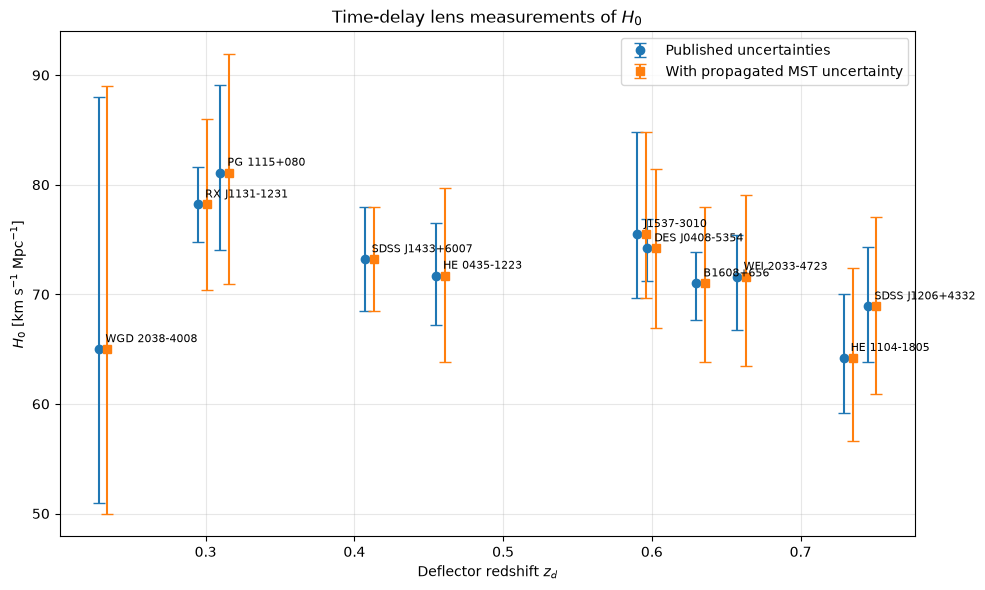

In [2]:
fig, ax = plt.subplots(figsize=(10, 6))

ax.errorbar(
    z,
    H0,
    yerr=[sigma_minus, sigma_plus],
    fmt="o",
    capsize=4,
    label="Published uncertainties"
)

ax.errorbar(
    z + 0.006,
    H0,
    yerr=[sigma_minus_mst, sigma_plus_mst],
    fmt="s",
    capsize=4,
    label="With propagated MST uncertainty"
)

for i, name in enumerate(names):
    ax.annotate(
        name,
        (z[i], H0[i]),
        xytext=(5, 5),
        textcoords="offset points",
        fontsize=8
    )

ax.set_xlabel(r"Deflector redshift $z_d$")
ax.set_ylabel(r"$H_0$ [km s$^{-1}$ Mpc$^{-1}$]")
ax.set_title(r"Time-delay lens measurements of $H_0$")

ax.grid(alpha=0.3)
ax.legend()
plt.tight_layout()
plt.show()

In [3]:
def make_nll(x, y, err_minus, err_plus):

    def nll(theta, model="linear"):

        if model == "linear":
            prediction = theta[0] + theta[1] * x
        else:
            prediction = np.full(len(x), theta[0])

        residual = y - prediction

        # If the model is below the measured central value,
        # use the lower uncertainty.
        error = np.where(
            residual >= 0,
            err_minus,
            err_plus
        )

        return np.sum(
            0.5 * (residual / error)**2
            + np.log(err_minus + err_plus)
            - 0.5 * np.log(2 / np.pi)
        )

    return nll


def fit_model(x, y, err_minus, err_plus, model):

    nll = make_nll(x, y, err_minus, err_plus)

    if model == "linear":
        starts = [[73, 0], [80, -20], [65, 20]]
    else:
        starts = [[70], [75], [80]]

    fits = [
        minimize(
            nll,
            start,
            args=(model,),
            method="Nelder-Mead",
            options={"maxiter": 20000}
        )
        for start in starts
    ]

    return min(fits, key=lambda result: result.fun)


def analyse_trend(x, y, err_minus, err_plus):

    x_mean = np.mean(x)
    xc = x - x_mean

    linear_fit = fit_model(
        xc, y, err_minus, err_plus, "linear"
    )

    constant_fit = fit_model(
        xc, y, err_minus, err_plus, "constant"
    )

    nll = make_nll(xc, y, err_minus, err_plus)

    slope = linear_fit.x[1]

    # Profile likelihood: optimise the intercept for each fixed slope
    def profile_nll(slope_value):

        return minimize_scalar(
            lambda intercept: nll(
                [intercept, slope_value],
                "linear"
            ),
            bounds=(20, 140),
            method="bounded"
        ).fun

    target = linear_fit.fun + 0.5 * chi2.ppf(0.95, 1)

    span = max(5 * abs(slope), 60)

    lower = brentq(
        lambda value: profile_nll(value) - target,
        slope - span,
        slope
    )

    upper = brentq(
        lambda value: profile_nll(value) - target,
        slope,
        slope + span
    )

    LR = 2 * (constant_fit.fun - linear_fit.fun)

    p_value = chi2.sf(max(LR, 0), 1)

    significance = norm.isf(p_value / 2)

    return {
        "slope": slope,
        "lower_95": lower,
        "upper_95": upper,
        "LR": LR,
        "p": p_value,
        "significance": significance,
        "intercept": linear_fit.x[0],
        "constant": constant_fit.x[0]
    }


def print_result(label, result):

    print(label)

    print(
        f"Slope = {result['slope']:.2f} "
        f"[{result['lower_95']:.2f}, "
        f"{result['upper_95']:.2f}]"
    )

    print(
        f"Likelihood-ratio significance: "
        f"{result['significance']:.2f} sigma"
    )

    print(f"p-value = {result['p']:.4f}")
    print()

In [4]:
# Case A: the nine lenses whose lambda_int was fixed to 1
mask_fixed = lambda_fixed

result_nine = analyse_trend(
    z[mask_fixed],
    H0[mask_fixed],
    sigma_minus[mask_fixed],
    sigma_plus[mask_fixed]
)

# Case B: all 11 lenses, with propagated MST uncertainties
result_eleven = analyse_trend(
    z,
    H0,
    sigma_minus_mst,
    sigma_plus_mst
)

print_result(
    "Nine lenses: original published errors",
    result_nine
)

print_result(
    "All 11 lenses: propagated MST errors",
    result_eleven
)

Nine lenses: original published errors
Slope = -21.29 [-39.89, -2.76]
Likelihood-ratio significance: 2.25 sigma
p-value = 0.0242

All 11 lenses: propagated MST errors
Slope = -17.30 [-47.50, 12.86]
Likelihood-ratio significance: 1.12 sigma
p-value = 0.2619



sigma_lambda = 0.000  slope = -19.53  significance = 2.15 sigma
sigma_lambda = 0.010  slope = -19.54  significance = 2.11 sigma
sigma_lambda = 0.020  slope = -19.52  significance = 2.02 sigma
sigma_lambda = 0.030  slope = -19.47  significance = 1.89 sigma
sigma_lambda = 0.040  slope = -19.33  significance = 1.74 sigma
sigma_lambda = 0.050  slope = -19.10  significance = 1.60 sigma
sigma_lambda = 0.060  slope = -18.77  significance = 1.47 sigma
sigma_lambda = 0.070  slope = -18.35  significance = 1.34 sigma
sigma_lambda = 0.080  slope = -17.85  significance = 1.23 sigma
sigma_lambda = 0.090  slope = -17.28  significance = 1.12 sigma
sigma_lambda = 0.100  slope = -16.66  significance = 1.02 sigma
sigma_lambda = 0.110  slope = -15.98  significance = 0.93 sigma
sigma_lambda = 0.120  slope = -15.28  significance = 0.85 sigma
sigma_lambda = 0.130  slope = -14.54  significance = 0.78 sigma
sigma_lambda = 0.140  slope = -13.79  significance = 0.71 sigma


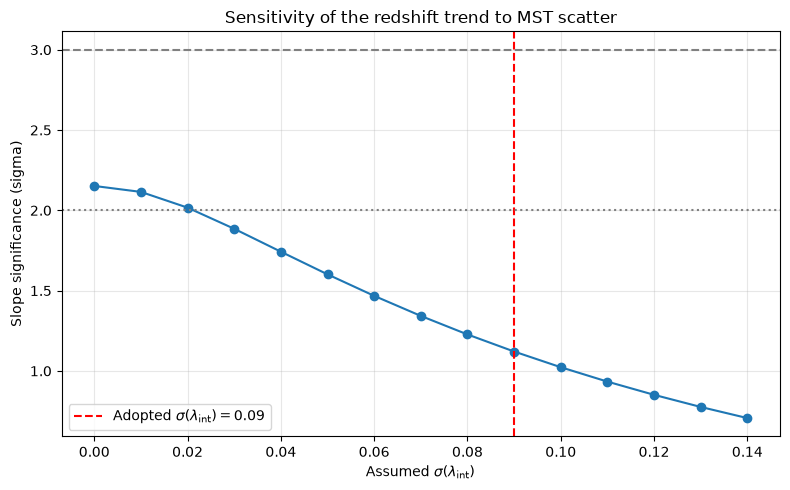

In [5]:
def add_mst_scatter(frac):

    extra_error = np.where(
        lambda_fixed,
        H0 * frac,
        0.0
    )

    new_minus = np.sqrt(
        sigma_minus**2 + extra_error**2
    )

    new_plus = np.sqrt(
        sigma_plus**2 + extra_error**2
    )

    return new_minus, new_plus


fractions = np.linspace(0, 0.14, 15)

slopes = []
significances = []

for frac in fractions:

    err_minus, err_plus = add_mst_scatter(frac)

    result = analyse_trend(
        z,
        H0,
        err_minus,
        err_plus
    )

    slopes.append(result["slope"])
    significances.append(result["significance"])

    print(
        f"sigma_lambda = {frac:.3f}  "
        f"slope = {result['slope']:.2f}  "
        f"significance = {result['significance']:.2f} sigma"
    )


fig, ax = plt.subplots(figsize=(8, 5))

ax.plot(
    fractions,
    significances,
    "o-"
)

ax.axvline(
    0.09,
    color="red",
    linestyle="--",
    label=r"Adopted $\sigma(\lambda_{\rm int})=0.09$"
)

ax.axhline(
    2,
    color="grey",
    linestyle=":"
)

ax.axhline(
    3,
    color="grey",
    linestyle="--"
)

ax.set_xlabel(r"Assumed $\sigma(\lambda_{\rm int})$")
ax.set_ylabel("Slope significance (sigma)")
ax.set_title("Sensitivity of the redshift trend to MST scatter")

ax.grid(alpha=0.3)
ax.legend()
plt.tight_layout()
plt.show()

In [6]:
# Symmetric approximation to the MST-inflated uncertainties
forecast_errors = (
    sigma_minus_mst + sigma_plus_mst
) / 2

# Empirical redshift distribution of the current sample
forecast_redshifts = z.copy()

# Reference redshift for the forecast model
z_reference = np.mean(forecast_redshifts)

# Assumed value of H0 at the reference redshift
H0_reference = 73.0

# Additional intrinsic scatter, in km/s/Mpc.
# Start with zero; later test non-zero values.
intrinsic_scatter = 0.0

print("Redshift reference:", z_reference)
print("Mean measurement uncertainty:", np.mean(forecast_errors))
print("Intrinsic scatter:", intrinsic_scatter)

Redshift reference: 0.513
Mean measurement uncertainty: 8.745454545454546
Intrinsic scatter: 0.0


In [7]:
def simulate_survey(
    n_lenses,
    assumed_slope,
    n_simulations=3000,
    intrinsic_scatter=0.0,
    seed=None
):

    rng = np.random.default_rng(seed)

    # Draw future lens redshifts from the observed distribution
    simulated_z = rng.choice(
        forecast_redshifts,
        size=(n_simulations, n_lenses),
        replace=True
    )

    # Draw measurement errors from the current MST-inflated sample
    measurement_errors = rng.choice(
        forecast_errors,
        size=(n_simulations, n_lenses),
        replace=True
    )

    total_errors = np.sqrt(
        measurement_errors**2 + intrinsic_scatter**2
    )

    # Generate H0 measurements under the assumed true slope
    true_values = (
        H0_reference
        + assumed_slope * (simulated_z - z_reference)
    )

    simulated_H0 = (
        true_values
        + rng.normal(size=(n_simulations, n_lenses))
        * total_errors
    )

    # Weighted linear regression for every simulated survey
    weights = 1 / total_errors**2

    weighted_z_mean = (
        np.sum(weights * simulated_z, axis=1)
        / np.sum(weights, axis=1)
    )

    weighted_H0_mean = (
        np.sum(weights * simulated_H0, axis=1)
        / np.sum(weights, axis=1)
    )

    dz = simulated_z - weighted_z_mean[:, None]
    dH0 = simulated_H0 - weighted_H0_mean[:, None]

    denominator = np.sum(weights * dz**2, axis=1)

    fitted_slopes = (
        np.sum(weights * dz * dH0, axis=1)
        / denominator
    )

    slope_errors = np.sqrt(1 / denominator)

    significance = np.abs(
        fitted_slopes / slope_errors
    )

    return fitted_slopes, significance

In [8]:
assumed_slopes = [-10, -20, -30]

lens_numbers = np.arange(5, 251, 5)

n_simulations = 3000

target_power = 0.80

thresholds = {
    "2 sigma": 2.0,
    "3 sigma": 3.0
}

forecast_results = []

for slope in assumed_slopes:

    for n in lens_numbers:

        fitted_slopes, significance = simulate_survey(
            n_lenses=n,
            assumed_slope=slope,
            n_simulations=n_simulations,
            intrinsic_scatter=intrinsic_scatter,
            seed=42 + n + abs(slope)
        )

        for label, threshold in thresholds.items():

            power = np.mean(significance >= threshold)

            forecast_results.append({
                "Assumed slope": slope,
                "Number of lenses": n,
                "Threshold": label,
                "Detection probability": power
            })


forecast_results = pd.DataFrame(forecast_results)

display(forecast_results.head(12))

/tmp/ipykernel_3516/3306833467.py:60: RuntimeWarning: invalid value encountered in divide
  np.sum(weights * dz * dH0, axis=1)
/tmp/ipykernel_3516/3306833467.py:64: RuntimeWarning: divide by zero encountered in divide
  slope_errors = np.sqrt(1 / denominator)


,Assumed slope,Number of lenses,Threshold,Detection probability
0,-10,5,2 sigma,0.074667
1,-10,5,3 sigma,0.007667
2,-10,10,2 sigma,0.098000
3,-10,10,3 sigma,0.012667
4,-10,15,2 sigma,0.127000
5,-10,15,3 sigma,0.018667
6,-10,20,2 sigma,0.156000
7,-10,20,3 sigma,0.022000
8,-10,25,2 sigma,0.195333
9,-10,25,3 sigma,0.032333


In [9]:
required_lenses = []

for slope in assumed_slopes:

    for label in thresholds:

        subset = forecast_results[
            (forecast_results["Assumed slope"] == slope)
            & (forecast_results["Threshold"] == label)
        ]

        successful = subset[
            subset["Detection probability"] >= target_power
        ]

        if len(successful) > 0:
            required_n = successful.iloc[0]["Number of lenses"]
        else:
            required_n = np.nan

        required_lenses.append({
            "Assumed slope": slope,
            "Target significance": label,
            "Required lenses for 80% power": required_n
        })


required_lenses = pd.DataFrame(required_lenses)

display(required_lenses)

,Assumed slope,Target significance,Required lenses for 80% power
0,-10,2 sigma,160.0
1,-10,3 sigma,NaN
2,-20,2 sigma,40.0
3,-20,3 sigma,75.0
4,-30,2 sigma,20.0
5,-30,3 sigma,35.0


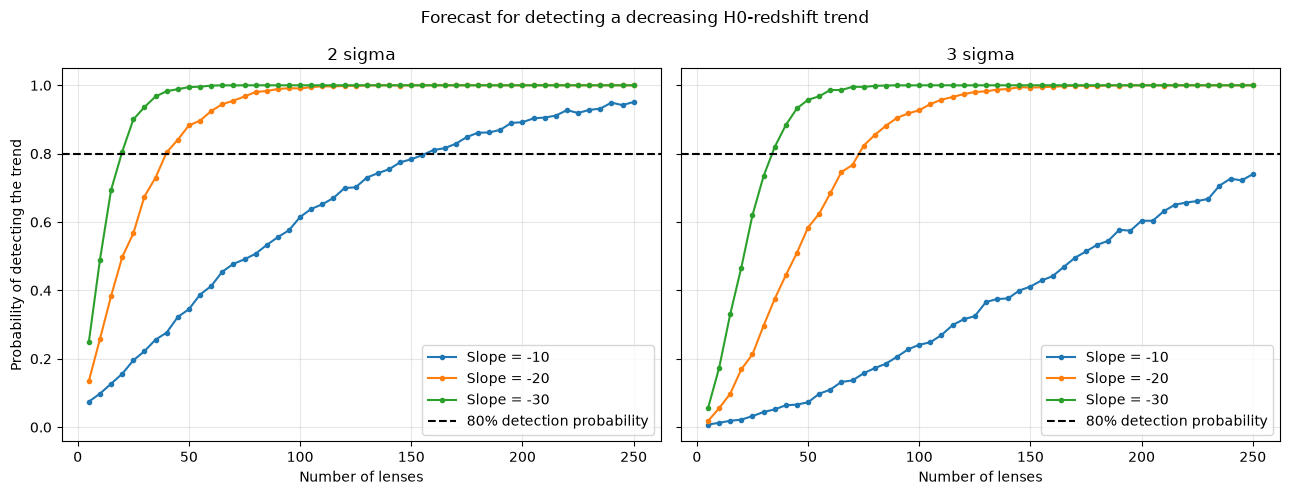

In [10]:
fig, axes = plt.subplots(
    1, 2,
    figsize=(13, 5),
    sharey=True
)

for ax, (label, threshold) in zip(
    axes,
    thresholds.items()
):

    for slope in assumed_slopes:

        subset = forecast_results[
            (forecast_results["Assumed slope"] == slope)
            & (forecast_results["Threshold"] == label)
        ]

        ax.plot(
            subset["Number of lenses"],
            subset["Detection probability"],
            marker="o",
            markersize=3,
            label=f"Slope = {slope}"
        )

    ax.axhline(
        target_power,
        color="black",
        linestyle="--",
        label="80% detection probability"
    )

    ax.set_xlabel("Number of lenses")
    ax.set_title(label)
    ax.grid(alpha=0.3)
    ax.legend()

axes[0].set_ylabel("Probability of detecting the trend")

fig.suptitle("Forecast for detecting a decreasing H0-redshift trend")

plt.tight_layout()
plt.show()

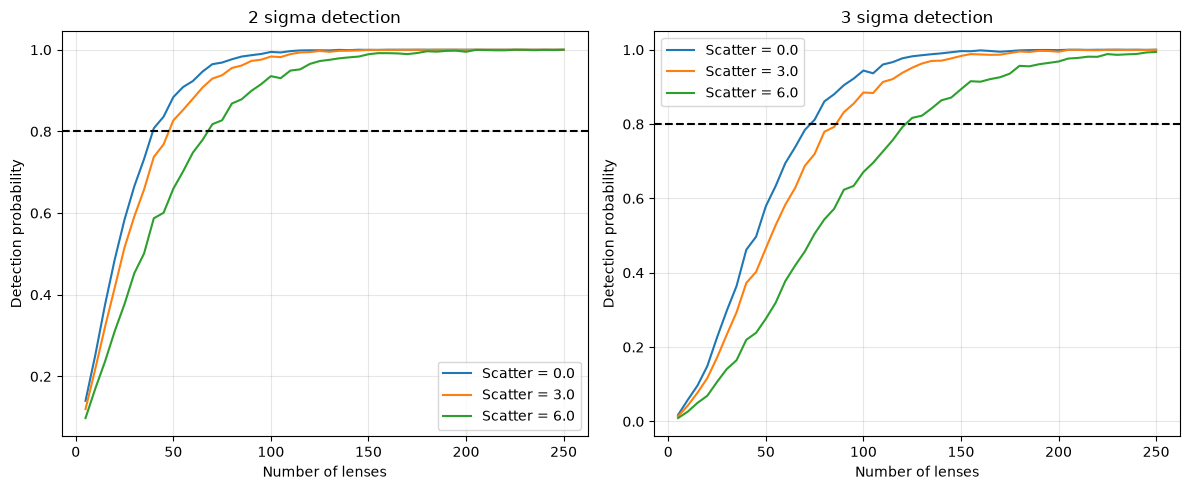

In [11]:
scatter_values = [0.0, 3.0, 6.0]

sensitivity_results = []

for scatter in scatter_values:

    for n in lens_numbers:

        _, significance = simulate_survey(
            n_lenses=n,
            assumed_slope=-20,
            n_simulations=3000,
            intrinsic_scatter=scatter,
            seed=1000 + n
        )

        sensitivity_results.append({
            "Intrinsic scatter": scatter,
            "Number of lenses": n,
            "Power at 2 sigma": np.mean(significance >= 2),
            "Power at 3 sigma": np.mean(significance >= 3)
        })


sensitivity_results = pd.DataFrame(sensitivity_results)

fig, axes = plt.subplots(1, 2, figsize=(12, 5))

for scatter in scatter_values:

    subset = sensitivity_results[
        sensitivity_results["Intrinsic scatter"] == scatter
    ]

    axes[0].plot(
        subset["Number of lenses"],
        subset["Power at 2 sigma"],
        label=f"Scatter = {scatter}"
    )

    axes[1].plot(
        subset["Number of lenses"],
        subset["Power at 3 sigma"],
        label=f"Scatter = {scatter}"
    )

for ax in axes:
    ax.axhline(0.80, color="black", linestyle="--")
    ax.set_xlabel("Number of lenses")
    ax.set_ylabel("Detection probability")
    ax.grid(alpha=0.3)
    ax.legend()

axes[0].set_title("2 sigma detection")
axes[1].set_title("3 sigma detection")

plt.tight_layout()
plt.show()